In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from glob import glob

In [3]:
# Function to load and preprocess .wav files to generate spectrograms

##data augmentation
import os
import numpy as np
import librosa
import cv2
from glob import glob

# Function to augment audio data
def augment_audio(audio, sr):
    augmented_data = []
    
    # Time stretching
    stretched = librosa.effects.time_stretch(audio, rate=np.random.uniform(0.8, 1.2))  # Stretch between 80% to 120%
    augmented_data.append(stretched)
    
    # Pitch shifting
    pitched = librosa.effects.pitch_shift(y=audio, sr=sr, n_steps=np.random.uniform(-2, 2))  # Shift pitch by -2 to 2 semitones
    augmented_data.append(pitched)
    
    # Adding noise
    noise = np.random.randn(len(audio))
    noisy_audio = audio + 0.005 * noise  # Adding slight noise to audio
    augmented_data.append(noisy_audio)
    
    return augmented_data


# Function to load and preprocess .wav files with data augmentation to generate RGB spectrograms
def load_wav_and_annotations_with_augmentation(file_paths, annotation_path):
    X, y = [], []
    for file_path in file_paths:
        file_name = os.path.basename(file_path)
        annotation_file = os.path.join(annotation_path, file_name.replace('.wav', '.txt'))
        
        # Load .wav file
        audio, sr = librosa.load(file_path, sr=None)
        
        # Generate original spectrogram and append to X
        mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        mel_spec_db_resized = librosa.util.fix_length(mel_spec_db, size=128, axis=1)
        mel_spec_db_resized = ((mel_spec_db_resized - mel_spec_db_resized.min()) / 
                                (mel_spec_db_resized.max() - mel_spec_db_resized.min()) * 255).astype(np.uint8)
        mel_spec_rgb = cv2.applyColorMap(mel_spec_db_resized, cv2.COLORMAP_JET)
        X.append(mel_spec_rgb)
        
        # Load corresponding annotations and determine the overall label for the audio file
        crackle_present = False
        wheeze_present = False
        
        with open(annotation_file, 'r') as f:
            for line in f:
                data = line.strip().split('\t')
                if int(data[2]) == 1:  # Crackle present in any cycle
                    crackle_present = True
                if int(data[3]) == 1:  # Wheeze present in any cycle
                    wheeze_present = True
        
        # Assign a single label to the entire file based on the overall presence of crackles and/or wheezes
        if crackle_present:
            label = 'crackles'
        elif wheeze_present:
            label = 'wheezes'
        else:
            label = 'normal'
        
        y.append(label)
        
        # Apply augmentations
        augmented_audios = augment_audio(audio, sr)
        
        for augmented_audio in augmented_audios:
            mel_spec_aug = librosa.feature.melspectrogram(y=augmented_audio, sr=sr)
            mel_spec_db_aug = librosa.power_to_db(mel_spec_aug, ref=np.max)
            mel_spec_db_resized_aug = librosa.util.fix_length(mel_spec_db_aug, size=128, axis=1)
            mel_spec_db_resized_aug = ((mel_spec_db_resized_aug - mel_spec_db_resized_aug.min()) / 
                                        (mel_spec_db_resized_aug.max() - mel_spec_db_resized_aug.min()) * 255).astype(np.uint8)
            mel_spec_rgb_aug = cv2.applyColorMap(mel_spec_db_resized_aug, cv2.COLORMAP_JET)
            X.append(mel_spec_rgb_aug)
            y.append(label)  # Use the same label for augmented data

    # Convert list to numpy array for model input
    X = np.array(X)
    y = np.array(y)
    
    return X, y


# Example: Load the dataset (adjust paths as needed)
wav_file_paths = glob('ICBHI_final_database/wav_files/**/*.wav', recursive=True)  # Adjust the path to match your actual folder structure
annotation_path = 'ICBHI_final_database/annotations/'  # Ensure the correct path for annotation files

X, y = load_wav_and_annotations_with_augmentation(wav_file_paths, annotation_path)

In [5]:
# Encode labels

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Encode labels if not already done
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)  # Converts labels to integers
y_categorical = to_categorical(y_encoded, num_classes=3)  # Converts to one-hot encoding (for 3 classes)

# Proceed with the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Check the shape after splitting
print("X_train shape before reshaping:", X_train.shape)
print("X_test shape before reshaping:", X_test.shape)

# Ensure correct reshaping for CNN (add channel dimension)
# Since X is already RGB, we expect it to be (num_samples, 128, 128, 3)
if X_train.ndim == 3:  # This should not occur if X is RGB
    raise ValueError("X_train should have 4 dimensions for RGB data")
elif X_train.ndim == 4:
    # No need to reshape, but you can check the shape
    if X_train.shape[3] != 3:
        raise ValueError("X_train must have 3 channels for RGB data")

print("Training data shape for ResNet:", X_train.shape)
print("Test data shape for ResNet:", X_test.shape)



X_train shape before reshaping: (2480, 128, 128, 3)
X_test shape before reshaping: (620, 128, 128, 3)
Training data shape for ResNet: (2480, 128, 128, 3)
Test data shape for ResNet: (620, 128, 128, 3)


In [ ]:
X, y = load_wav_and_annotations_with_augmentation(wav_file_paths, annotation_path)
print(f"Number of spectrograms (X): {len(X)}")
print(f"Number of labels (y): {len(y)}")

In [7]:
# Define a CNN model for lung sound classification using an Input layer
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, optimizers

# Load ResNet50 without the top layers
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

# Freeze the base model layers
base_model.trainable = False  # Initially freeze the layers

# Build your model on top of ResNet50
def create_transfer_model():
    model = models.Sequential()

    # Add ResNet50 as the feature extractor
    model.add(base_model)

    # Add global pooling
    model.add(layers.GlobalAveragePooling2D())

    # Dense layer to learn new features
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))

    # Output layer for 3 classes
    model.add(layers.Dense(3, activation='softmax'))

    # Compile the model with a lower learning rate
    model.compile(optimizer=optimizers.Adam(learning_rate=0.0001),  # Lower learning rate
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model

# Create and summarize the model
transfer_model = create_transfer_model()
transfer_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [11]:
# OPTIONAL: Fine-tune some layers of ResNet after initial training
def fine_tune_transfer_model(model, base_model, num_fine_tune_layers=50):
    # Unfreeze the top layers of ResNet for fine-tuning
    base_model.trainable = True
    
    # Freeze all layers except the last `num_fine_tune_layers` layers
    for layer in base_model.layers[:-num_fine_tune_layers]:
        layer.trainable = False

    # Recompile the model with a lower learning rate for fine-tuning
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),  # Even lower learning rate for fine-tuning
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model

# Optionally fine-tune the model
transfer_model = fine_tune_transfer_model(transfer_model, base_model)

In [13]:
# Unfreeze the top 50 layers for fine-tuning
transfer_model = fine_tune_transfer_model(transfer_model, base_model, num_fine_tune_layers=50)

# Fine-tune the model with a lower learning rate
fine_tune_history = transfer_model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.4875 - loss: 1.2179 - val_accuracy: 0.6226 - val_loss: 0.8088
Epoch 2/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.6486 - loss: 0.8139 - val_accuracy: 0.6419 - val_loss: 0.7878
Epoch 3/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.7020 - loss: 0.6522 - val_accuracy: 0.6661 - val_loss: 0.7444
Epoch 4/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.7868 - loss: 0.5333 - val_accuracy: 0.6726 - val_loss: 0.7107
Epoch 5/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.8365 - loss: 0.4648 - val_accuracy: 0.6871 - val_loss: 0.6873
Epoch 6/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0.8669 - loss: 0.3960 - val_accuracy: 0.7048 - val_loss: 0.6542
Epoch 7/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.8977 - loss: 0.3137 - val_accuracy: 0.7306 - val_loss: 0.6223
Epoch 8/10
78/78 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.9360 - loss: 0.2448 - val_accuracy: 0.7129 - v

In [9]:
# Train the model
history = transfer_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 70s 768ms/step - accuracy: 0.4097 - loss: 1.7289 - val_accuracy: 0.5952 - val_loss: 0.9234
Epoch 2/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 761ms/step - accuracy: 0.5371 - loss: 1.0204 - val_accuracy: 0.6065 - val_loss: 0.8861
Epoch 3/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 753ms/step - accuracy: 0.5997 - loss: 0.9012 - val_accuracy: 0.6048 - val_loss: 0.8843
Epoch 4/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 760ms/step - accuracy: 0.6062 - loss: 0.8862 - val_accuracy: 0.6081 - val_loss: 0.8559
Epoch 5/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 758ms/step - accuracy: 0.6241 - loss: 0.8504 - val_accuracy: 0.6081 - val_loss: 0.8465
Epoch 6/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 754ms/step - accuracy: 0.6368 - loss: 0.8415 - val_accuracy: 0.6161 - val_loss: 0.8539
Epoch 7/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 759ms/step - accuracy: 0.6568 - loss: 0.8173 - val_accuracy: 0.6177 - val_loss: 0.8304
Epoch 8/20
78/78 ━━━━━━━━━━━━━━━━━━━━ 59s 764ms/step - accuracy: 0.6501 - loss: 0.8033 - val_accu

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 693ms/step


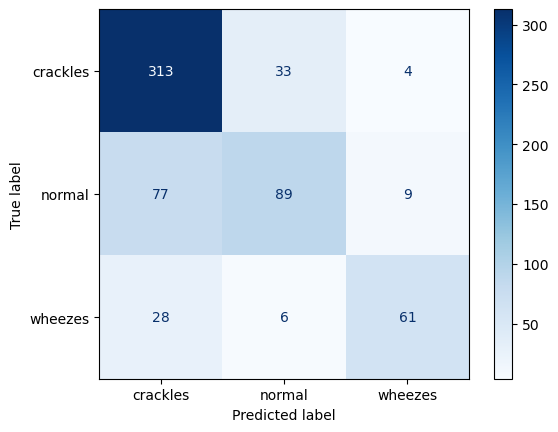

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Make predictions on the test set
y_pred = transfer_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show()


In [23]:
#### F1 score
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions on the test set
y_pred = transfer_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Print classification report (F1-score, precision, recall)
report = classification_report(y_true, y_pred_classes, target_names=label_encoder.classes_)
print(report)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:")
print(cm)

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 530ms/step
              precision    recall  f1-score   support

    crackles       0.75      0.89      0.82       350
      normal       0.70      0.51      0.59       175
     wheezes       0.82      0.64      0.72        95

    accuracy                           0.75       620
   macro avg       0.76      0.68      0.71       620
weighted avg       0.75      0.75      0.74       620

Confusion Matrix:
[[313  33   4]
 [ 77  89   9]
 [ 28   6  61]]


In [17]:
print(np.unique(y))
# to check labels

['crackles' 'normal' 'wheezes']


In [19]:
# Check the distribution of labels
unique, counts = np.unique(y, return_counts=True)
print(f"Label distribution: {dict(zip(unique, counts))}")


Label distribution: {'crackles': 1776, 'normal': 840, 'wheezes': 484}


In [29]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Generate the confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Define labels for clarity
class_names = ["Normal", "Crackles", "Wheezes"]

# Initialize lists to store sensitivity and specificity for each class
sensitivity = []
specificity = []

# Calculate sensitivity and specificity for each class
for i, class_name in enumerate(class_names):
    TP = cm[i, i]  # True Positives for class i
    FN = np.sum(cm[i, :]) - TP  # False Negatives for class i
    FP = np.sum(cm[:, i]) - TP  # False Positives for class i
    TN = np.sum(cm) - (TP + FN + FP)  # True Negatives for class i
    
    # Sensitivity (Recall)
    class_sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0
    sensitivity.append(class_sensitivity)
    
    # Specificity
    class_specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    specificity.append(class_specificity)
    
    print(f"{class_name} - Sensitivity: {class_sensitivity:.2f}, Specificity: {class_specificity:.2f}")

# Calculate the average score (average of sensitivity and specificity for each class)
average_sensitivity = np.mean(sensitivity)
average_specificity = np.mean(specificity)
score = (average_sensitivity + average_specificity) / 2

print(f"\nAverage Sensitivity: {average_sensitivity:.2f}")
print(f"Average Specificity: {average_specificity:.2f}")
print(f"Score (Average of Sensitivity and Specificity): {score:.2f}")


Normal - Sensitivity: 0.89, Specificity: 0.61
Crackles - Sensitivity: 0.51, Specificity: 0.91
Wheezes - Sensitivity: 0.64, Specificity: 0.98

Average Sensitivity: 0.68
Average Specificity: 0.83
Score (Average of Sensitivity and Specificity): 0.76


In [31]:
# Evaluate the model
test_loss, test_accuracy = transfer_model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 569ms/step - accuracy: 0.7385 - loss: 0.6776
Test Accuracy: 74.68%


In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Make predictions on the test set
y_pred = transfer_model.predict(X_test)

# Convert predicted probabilities to class predictions using argmax
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Print classification report (F1-score, precision, recall)
target_names = ["Normal", "Crackles", "Wheezes"]  # Update this according to your class labels
print("Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=target_names, zero_division=0))

# Confusion matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_true_classes, y_pred_classes)
print(cm)

# Analyze how many samples were predicted for each category
print("\nNumber of predicted 'Normal':", np.sum(y_pred_classes == 0))
print("Number of predicted 'Crackles':", np.sum(y_pred_classes == 1))
print("Number of predicted 'Wheezes':", np.sum(y_pred_classes == 2))

print("\nNumber of actual 'Normal':", np.sum(y_true_classes == 0))
print("Number of actual 'Crackles':", np.sum(y_true_classes == 1))
print("Number of actual 'Wheezes':", np.sum(y_true_classes == 2))


20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 560ms/step
Classification Report:
              precision    recall  f1-score   support

      Normal       0.75      0.89      0.82       350
    Crackles       0.70      0.51      0.59       175
     Wheezes       0.82      0.64      0.72        95

    accuracy                           0.75       620
   macro avg       0.76      0.68      0.71       620
weighted avg       0.75      0.75      0.74       620

Confusion Matrix:
[[313  33   4]
 [ 77  89   9]
 [ 28   6  61]]

Number of predicted 'Normal': 418
Number of predicted 'Crackles': 128
Number of predicted 'Wheezes': 74

Number of actual 'Normal': 350
Number of actual 'Crackles': 175
Number of actual 'Wheezes': 95


In [47]:
# Function to predict the label for a new .wav file
import os
import numpy as np
import librosa

# Function to predict the label for a new .wav file
def predict_lung_sounds(model, file_paths, label_encoder):
    for file_path in file_paths:
        # Load .wav file
        audio, sr = librosa.load(file_path, sr=None)
        
        # Generate mel-spectrogram
        mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Resize spectrogram to a fixed size (e.g. 128x128)
        mel_spec_db_resized = librosa.util.fix_length(mel_spec_db, size=128, axis=1)
        
        # Convert to RGB (3 channels)
        mel_spec_rgb = np.stack((mel_spec_db_resized,)*3, axis=-1)  # Stack to create 3 channels
        
        # Reshape for the model (1, height, width, channels)
        mel_spec_rgb = mel_spec_rgb.reshape(1, 128, 128, 3)
        
        # Predict using the model
        prediction = model.predict(mel_spec_rgb)
        predicted_class = np.argmax(prediction, axis=1)
        predicted_label = label_encoder.inverse_transform(predicted_class)
        
        print(f"Prediction for {os.path.basename(file_path)}: {predicted_label[0]}")

# User provides up to 3 recordings for left and right lungs (paths to .wav files)
left_lung_files = [
    r'C:\Users\ASUS\Downloads\LUNGS_CATEGORIAL\personalTEST\223_1b1_Ll_sc_Meditron.wav',
    r'C:\Users\ASUS\Downloads\LUNGS_CATEGORIAL\personalTEST\BP10_Asthma,E W,P R U,59,M.wav',
    r'C:\Users\ASUS\Downloads\an messup\wheezes\64743918_7.0_0_p3_2971.wav',
    r'C:\Users\ASUS\Downloads\an messup\wheezes\40976541_2.7_1_p1_3305.wav'
]
right_lung_files = [
    r'C:\Users\ASUS\Downloads\LUNGS_CATEGORIAL\personalTEST\223_1b1_Ar_sc_Meditron.wav',
    r'C:\Users\ASUS\Downloads\LUNGS_CATEGORIAL\personalTEST\_3.9_0_p2_16907.wav',
    r'C:\Users\ASUS\Downloads\LUNGS_CATEGORIAL\personalTEST\BP30_N,N,P R M,18,F.wav'
]

# Pass the trained label encoder and model
print("Left lung predictions:")
predict_lung_sounds(transfer_model, left_lung_files, label_encoder)

print("\nRight lung predictions:")
predict_lung_sounds(transfer_model, right_lung_files, label_encoder)


Left lung predictions:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
Prediction for 223_1b1_Ll_sc_Meditron.wav: crackles
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
Prediction for BP10_Asthma,E W,P R U,59,M.wav: normal
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
Prediction for 64743918_7.0_0_p3_2971.wav: wheezes
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
Prediction for 40976541_2.7_1_p1_3305.wav: normal

Right lung predictions:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
Prediction for 223_1b1_Ar_sc_Meditron.wav: crackles
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
Prediction for _3.9_0_p2_16907.wav: normal
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
Prediction for BP30_N,N,P R M,18,F.wav: normal


In [37]:
# Save the entire model
transfer_model.save('LungModel.h5')

In [ ]:
# Load the model
from tensorflow.keras.models import load_model

loaded_model = load_model('LungModel.h5')